In [1]:
from MultiAgent_DQ import *
import numpy as np
import pandas as pd  
import itertools
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import pandas as pd
import sys
sys.path.append('../')
import tqdm
from utils import *


## reading results from simulations

In [2]:
df = pd.read_csv("../results/results_from_vectorized_script_raw.csv")
df_fixed = pd.read_csv("../results/results_vect_paramsfixed_time.csv")
df_new = pd.read_csv('../results/results_vect_ADGT.csv')


In [3]:
#excluding lambda > 0.8
df_fixed = df_fixed[df_fixed['lambda']<=0.8]

In [4]:
def round_columns(df, columns, decimals):
    for column in columns:
        df[column] = df[column].round(decimals)
    return df

def round_to_quarters(df, columns, decimals):
    for column in columns:
        df[column] = (df[column]/ 0.25).round(decimals)* 0.25
    return df

# Columns to round
columns_to_round = ['delta', 'e', 'lambda', 'alpha']

# Apply the function to df
# Apply the function to df_fixed
df_fixed = round_columns(df_fixed, columns_to_round, 2)
df = round_columns(df, columns_to_round, 2)
df_new = round_columns(df_new, columns_to_round, 2)


df_fixed['M'] = df_fixed['M'].round(0)
df_new['M'] = df_new['M'].round(0)


In [5]:
columns = ['delta', 'e', 'lambda', 'alpha']

# Generate all pairwise combinations of the columns
pair_combinations = list(itertools.combinations(columns, 2))

# Display the pair combinations
print(pair_combinations)

[('delta', 'e'), ('delta', 'lambda'), ('delta', 'alpha'), ('e', 'lambda'), ('e', 'alpha'), ('lambda', 'alpha')]


/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/MultiAgent/../utils.py:705: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


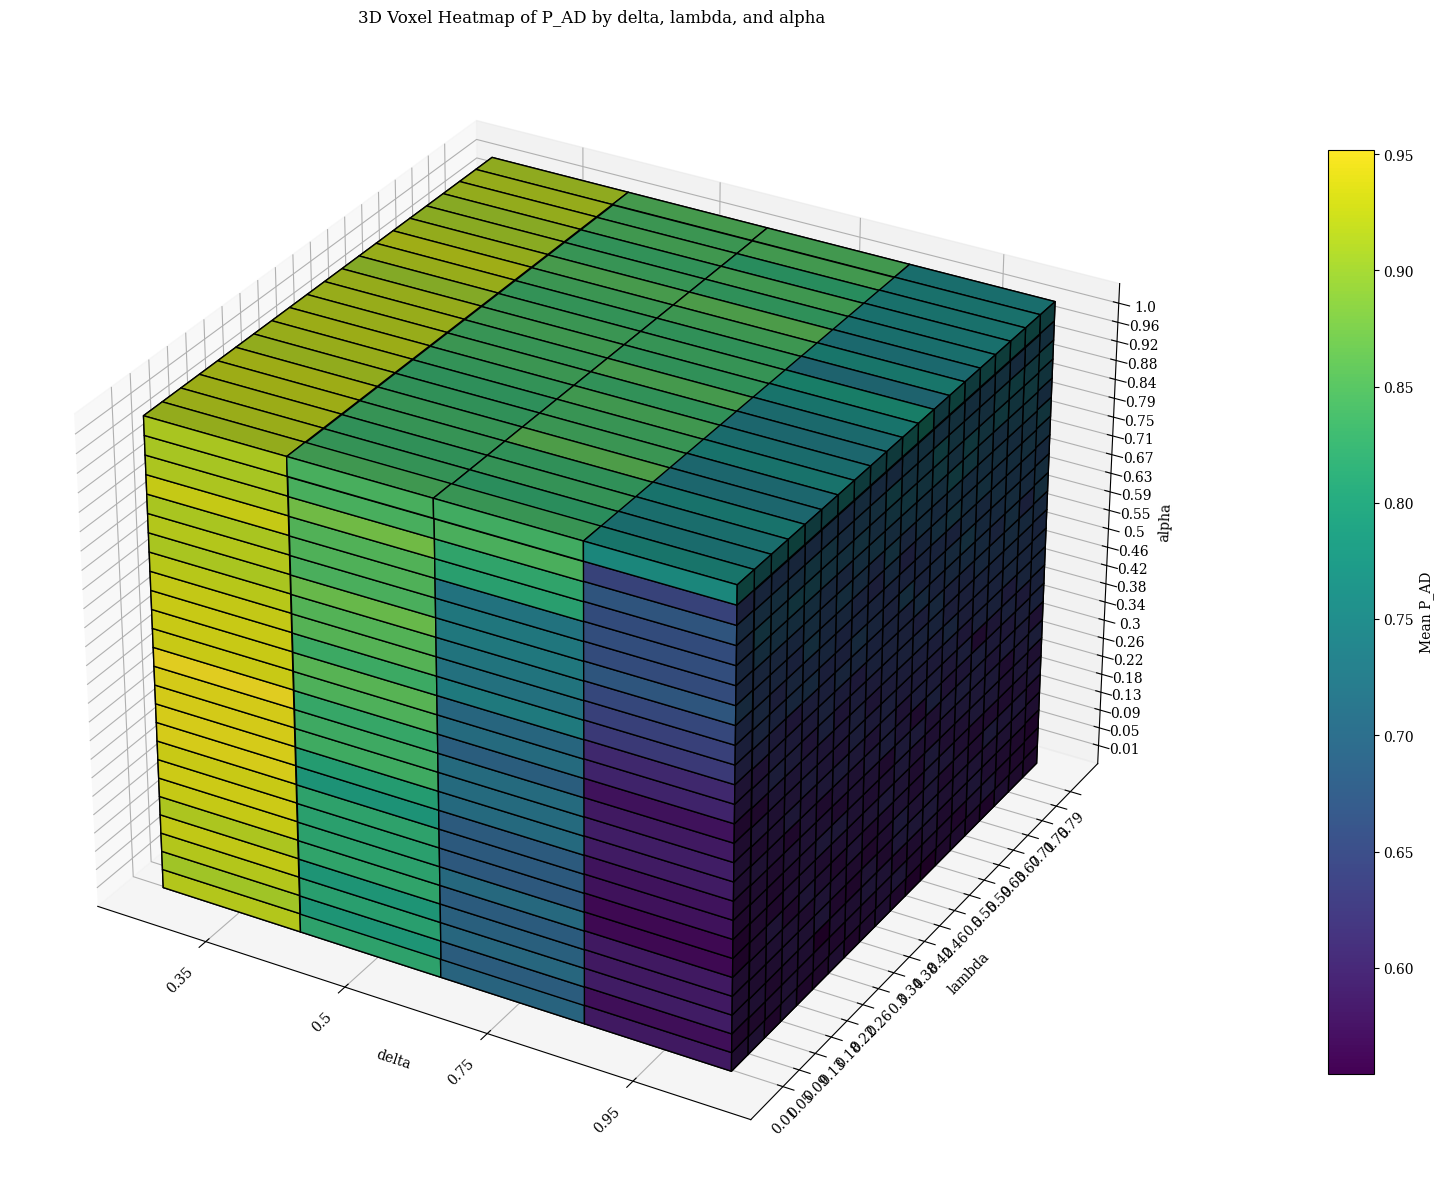

/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/MultiAgent/../utils.py:705: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


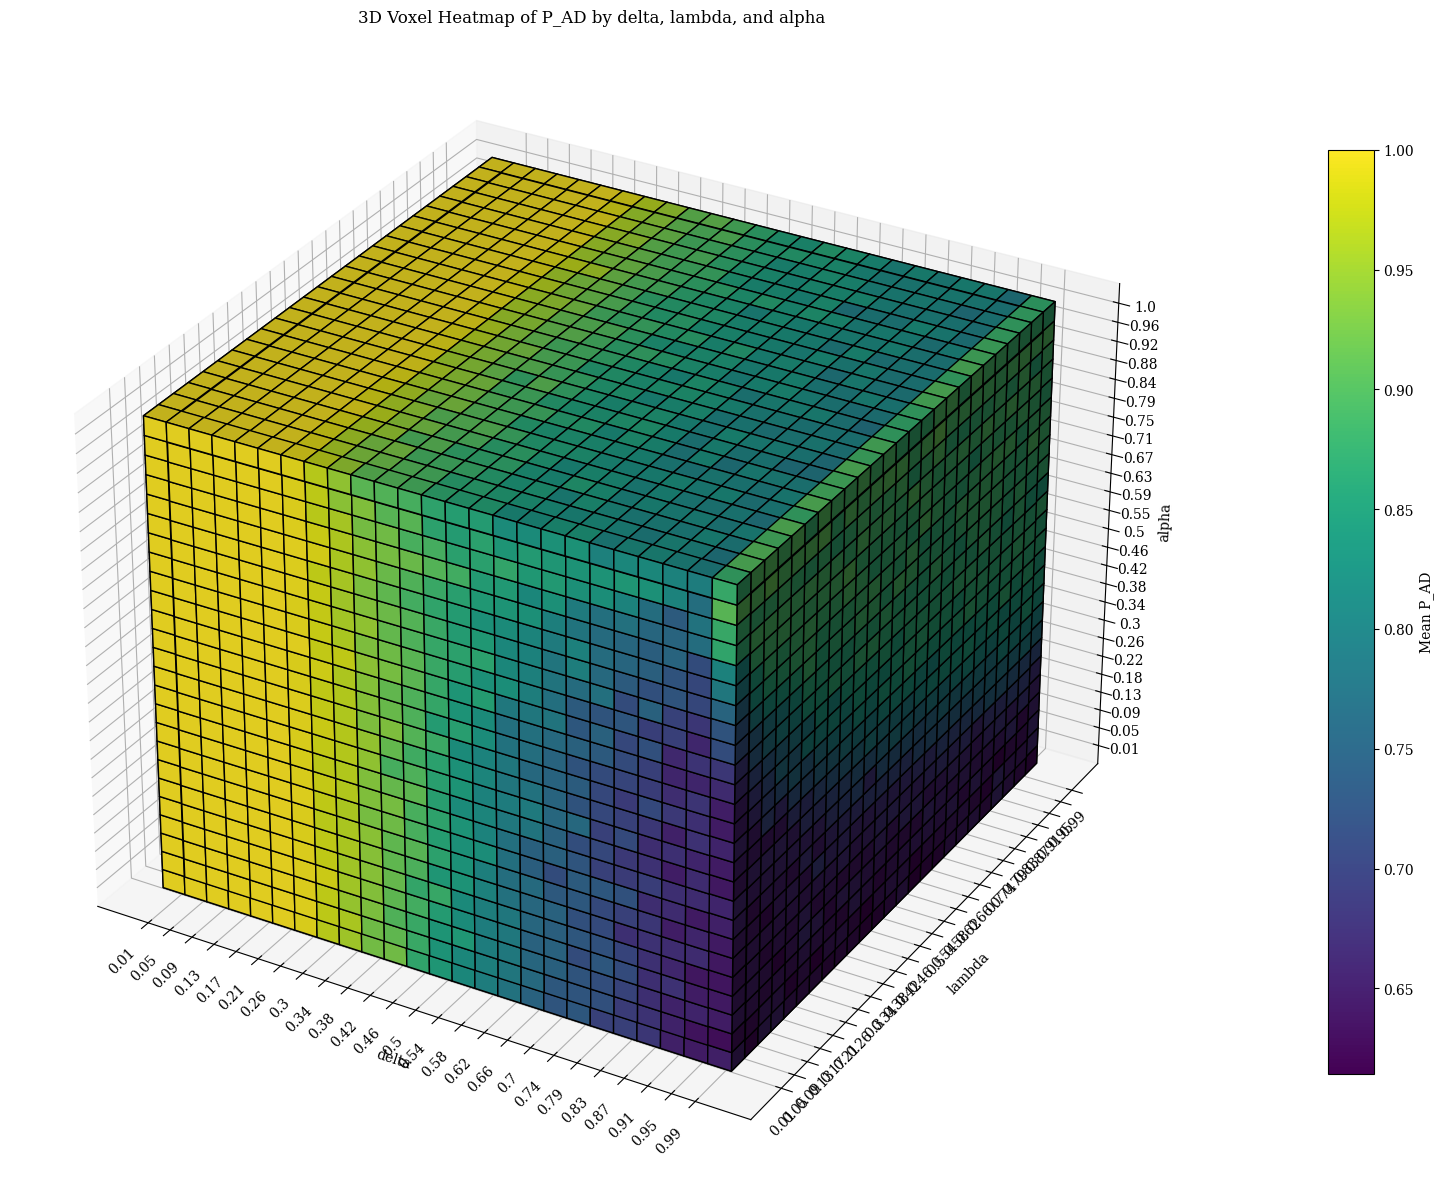

In [6]:
heatmap_3d_voxels(df_fixed, 'delta', 'lambda', 'alpha', value='P_AD')
heatmap_3d_voxels(df, 'delta', 'lambda', 'alpha', value='P_AD')


In [7]:
interactive_3d_voxel(df, 'delta', 'lambda', 'alpha', value='P_AD', html= False)

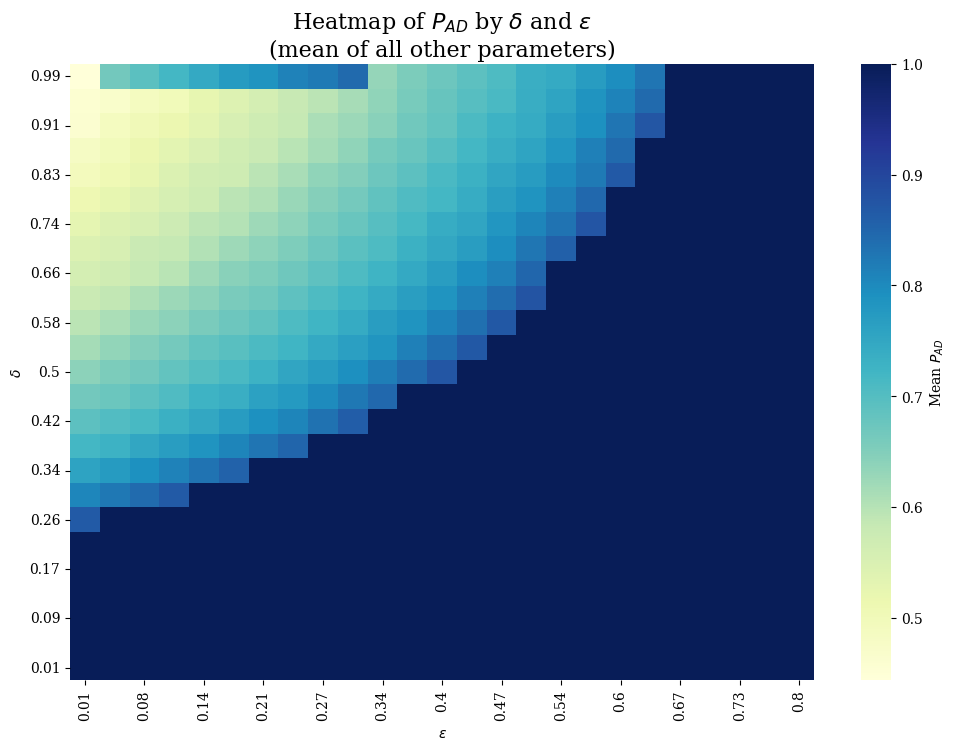

In [8]:
heatmap_mean(df, 'delta', 'e', 'P_AD')

In [9]:
#TODO: as alpha goes to 0, the effect of lambda in equilibrium decreases - flattening?
m = 5000

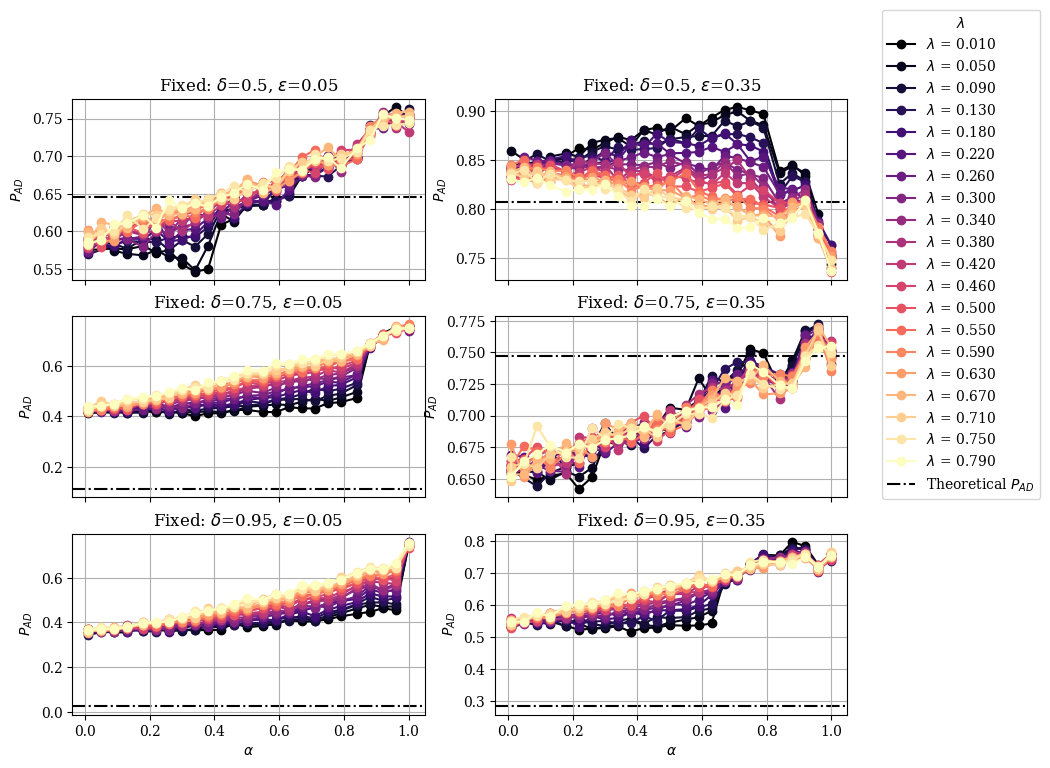

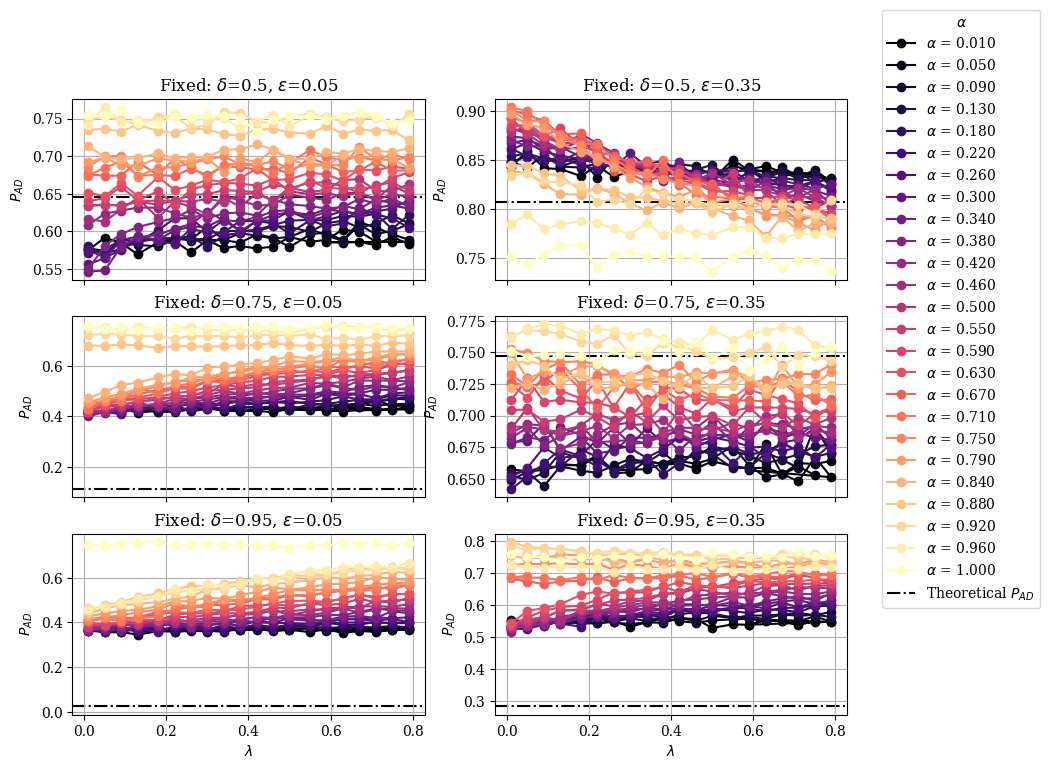

In [10]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.35},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.35},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.35},
]

m=5000
y = 'P_AD'

t, r, p, s = 1, 0.7, 0.2, 0
from MultiAgent.basin import theoretical_P_AD_from_ADGT

theoretical_per_panel = [theoretical_P_AD_from_ADGT(t=t, r=r, p=p, s=s, delta=ps['delta'], e=ps['e']) for ps in param_sets]
theoretical_per_panel_c_s = [theoretical_P_AD_from_ADGT(t=t, r=r, p=p, s=s, delta=ps['delta'], e=ps['e']) for ps in param_sets]

plot_multiple_panels(df_fixed, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=5000, use_same_scale=False, cmap = 'magma', theoretical_basin_AD=theoretical_per_panel_c_s)
plot_multiple_panels(df_fixed, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=5000, use_same_scale=False, cmap = 'magma', theoretical_basin_AD=theoretical_per_panel_c_s)

In [11]:
theoretical_per_panel

[0.6455026455026458,
 0.8071519795657711,
 0.11118405347338273,
 0.7474067844126748,
 0.02402135231316742,
 0.2836231142930234]

In [12]:
theoretical_per_panel_c_s

[0.6455026455026458,
 0.8071519795657711,
 0.11118405347338273,
 0.7474067844126748,
 0.02402135231316742,
 0.2836231142930234]

In [13]:
df_new['M'].unique()

array([ 20, 100, 500])

In [14]:
for ps in param_sets:
    delta=ps['delta']
    e=ps['e']
    print('delta:',delta, 'epsilon:',e)

delta: 0.5 epsilon: 0.05
delta: 0.5 epsilon: 0.35
delta: 0.75 epsilon: 0.05
delta: 0.75 epsilon: 0.35
delta: 0.95 epsilon: 0.05
delta: 0.95 epsilon: 0.35


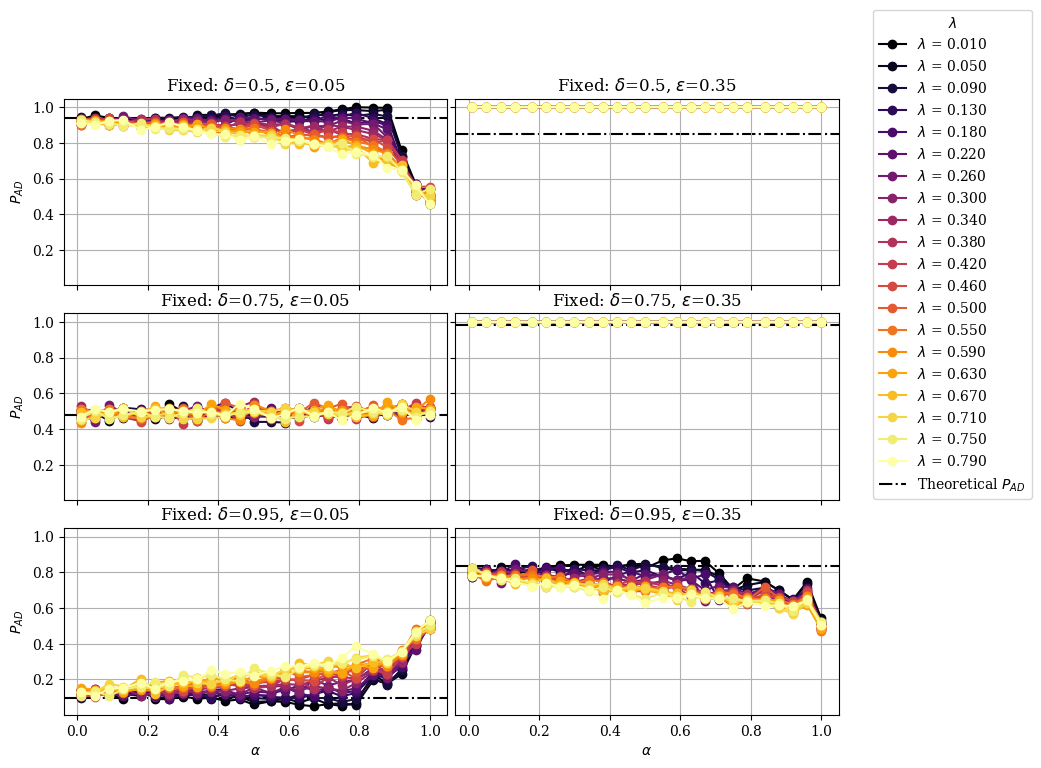

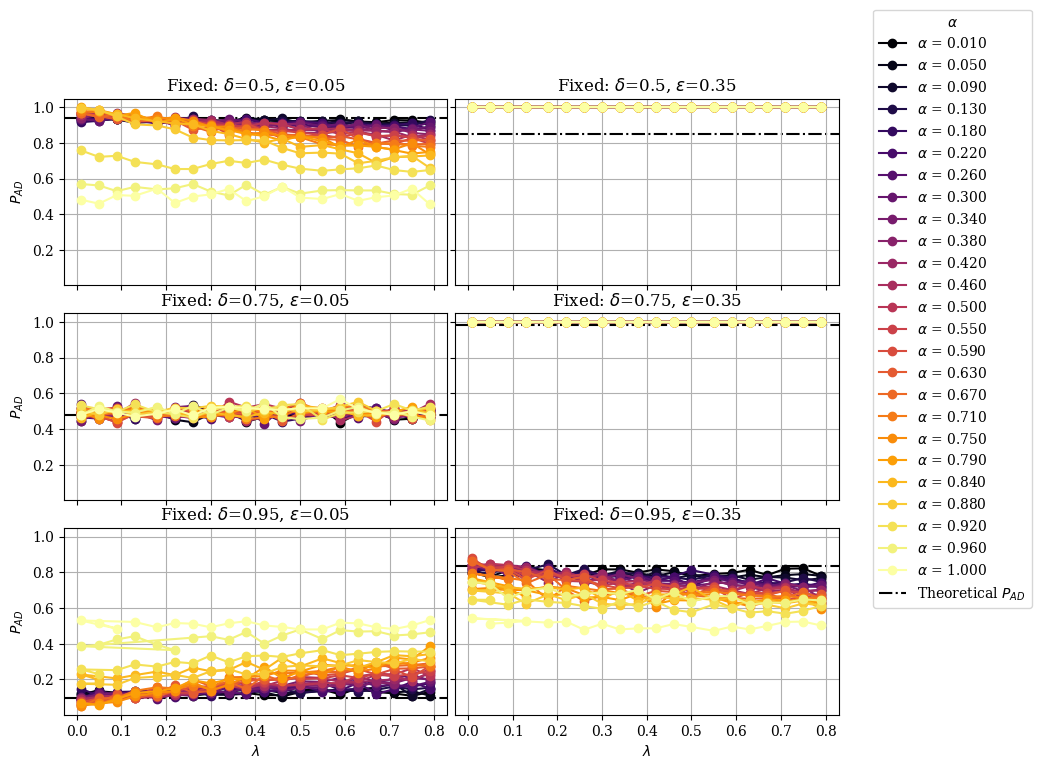

In [20]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.35},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.35},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.35},
]

m=500
y = 'P_AD'
from MultiAgent.basin import theoretical_P_AD_from_ADGT
theoretical_per_panel_c = [theoretical_P_AD_from_ADGT(t=1, r=0.8, p=0.5, s=0, delta=ps['delta'], e=ps['e']) for ps in param_sets]

plot_multiple_panels(df_new, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=500, use_same_scale=True, cmap = 'inferno', theoretical_basin_AD=theoretical_per_panel_c)
plot_multiple_panels(df_new, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=500, use_same_scale=True, cmap = 'inferno', theoretical_basin_AD=theoretical_per_panel_c)

In [16]:
theoretical_P_AD_from_ADGT(1, 0.7, 0.2, 0, 0.05,0.95,0)

0.02402135231316742

In [17]:
theoretical_P_AD_from_ADGT(1, 0.8, 0.5, 0, 0.05,0.95,0)

0.09850000000000037

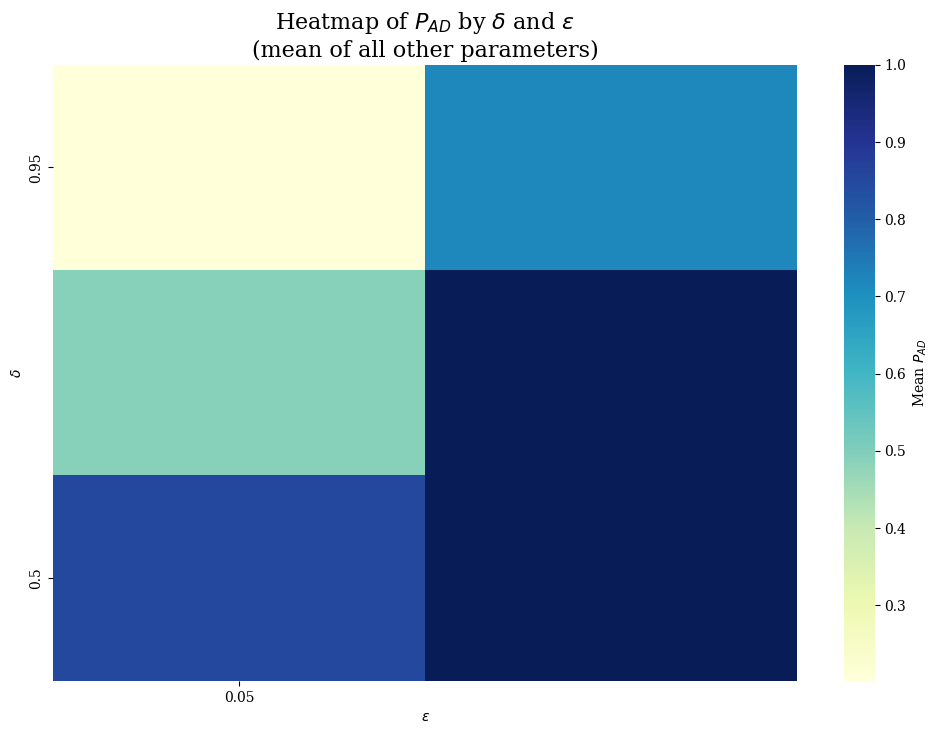

In [18]:
heatmap_mean(df_new, 'delta', 'e', 'P_AD')


In [19]:
theoretical_per_panel_c

[0.9419869470630894,
 0.851024208566108,
 0.47594537815126237,
 0.9809238315846865,
 0.09850000000000037,
 0.8356884653302608]